Parameters defined successfully!
Data generation function defined successfully!
Class 1 shape: (1000, 2)
Class 2 shape: (1000, 2)
Combined data shape: (2000, 2)
Total samples: 2000


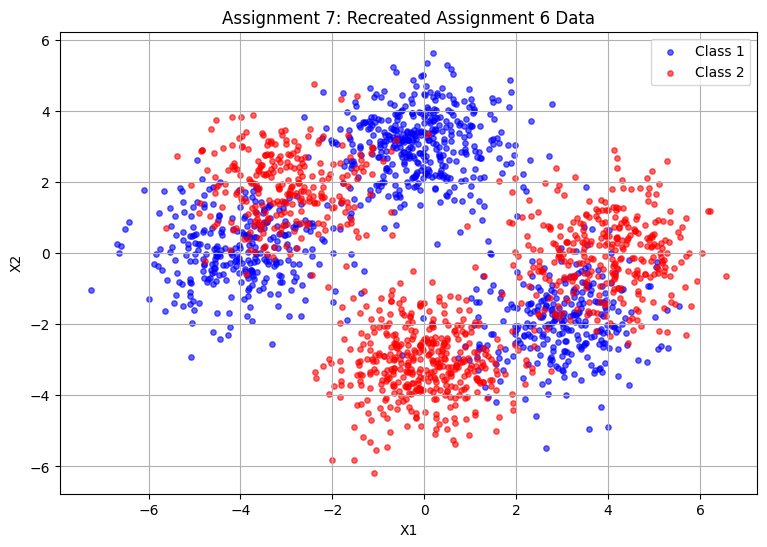

In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Reproducible random numbers
np.random.seed(42)


# Number of samples per class
N = 1000

# Number of Gaussian components per class
K = 3

# Mixture weights
weights = [0.3, 0.4, 0.3]

# Means for Class 1
means_1 = [
    [-4, 0],
    [0, 3],
    [3, -2]
]

# Means for Class 2
means_2 = [
    [4, 0],
    [0, -3],
    [-3, 2]
]

# Spherical covariance
cov_spherical = [
    [[1, 0], [0, 1]],
    [[1, 0], [0, 1]],
    [[1, 0], [0, 1]]
]

# Diagonal covariance
cov_diagonal = [
    [[2.0, 0], [0, 0.5]],
    [[0.5, 0], [0, 2.0]],
    [[1.5, 0], [0, 0.7]]
]

# Full covariance
cov_full = [
    [[2.0, 0.8], [0.8, 1.0]],
    [[1.0, -0.6], [-0.6, 1.5]],
    [[1.5, 0.7], [0.7, 1.0]]
]

print("Parameters defined successfully!")

def generate_data(N, means, weights, covariances):
    data = []
    component_labels = []

    for _ in range(N):

        # Select a Gaussian component
        component = np.random.choice(
            len(weights), p=weights
        )

        # Generate a two-dimensional sample
        point = np.random.multivariate_normal(
            means[component],
            covariances[component]
        )

        data.append(point)
        component_labels.append(component)

    return np.array(data), np.array(component_labels)


print("Data generation function defined successfully!")

# Generate Class 1 and Class 2
X1, components1 = generate_data(
    N, means_1, weights, cov_spherical
)

X2, components2 = generate_data(
    N, means_2, weights, cov_spherical
)

# Combine the data
X = np.vstack((X1, X2))

# Class labels: 0 = Class 1, 1 = Class 2
y = np.array([0] * len(X1) + [1] * len(X2))

print("Class 1 shape:", X1.shape)
print("Class 2 shape:", X2.shape)
print("Combined data shape:", X.shape)
print("Total samples:", len(X))

plt.figure(figsize=(9, 6))

plt.scatter(
    X1[:, 0], X1[:, 1],
    color="blue", label="Class 1",
    alpha=0.6, s=15
)

plt.scatter(
    X2[:, 0], X2[:, 1],
    color="red", label="Class 2",
    alpha=0.6, s=15
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Assignment 7: Recreated Assignment 6 Data")
plt.legend()
plt.grid(True)
plt.show()


In [7]:

X1_train, X1_test = train_test_split(
    X1, test_size=0.2, random_state=42
)

X2_train, X2_test = train_test_split(
    X2, test_size=0.2, random_state=42
)

print("Class 1 training samples:", len(X1_train))
print("Class 1 testing samples:", len(X1_test))

print("Class 2 training samples:", len(X2_train))
print("Class 2 testing samples:", len(X2_test))


Class 1 training samples: 800
Class 1 testing samples: 200
Class 2 training samples: 800
Class 2 testing samples: 200


In [8]:

# Create separate GMM models
gmm_class1 = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=3,
    reg_covar=1e-6
)

gmm_class2 = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=3,
    reg_covar=1e-6
)

# Train using only the training data
gmm_class1.fit(X1_train)
gmm_class2.fit(X2_train)

print("GMM for Class 1 trained successfully!")
print("GMM for Class 2 trained successfully!")


GMM for Class 1 trained successfully!
GMM for Class 2 trained successfully!


In [9]:

# Combine test data and true labels
X_test = np.vstack((X1_test, X2_test))

y_test = np.array(
    [0] * len(X1_test) + [1] * len(X2_test)
)

# Calculate log-likelihood under each class model
scores_class1 = gmm_class1.score_samples(X_test)
scores_class2 = gmm_class2.score_samples(X_test)

# Predict the class with higher log-likelihood
y_pred = (scores_class2 > scores_class1).astype(int)

print("Classification completed!")

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("GMM Classification Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Class 1", "Class 2"],
    zero_division=0
))


Classification completed!
GMM Classification Accuracy: 87.0 %

Confusion Matrix:
[[173  27]
 [ 25 175]]

Classification Report:
              precision    recall  f1-score   support

     Class 1       0.87      0.86      0.87       200
     Class 2       0.87      0.88      0.87       200

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87       400
weighted avg       0.87      0.87      0.87       400



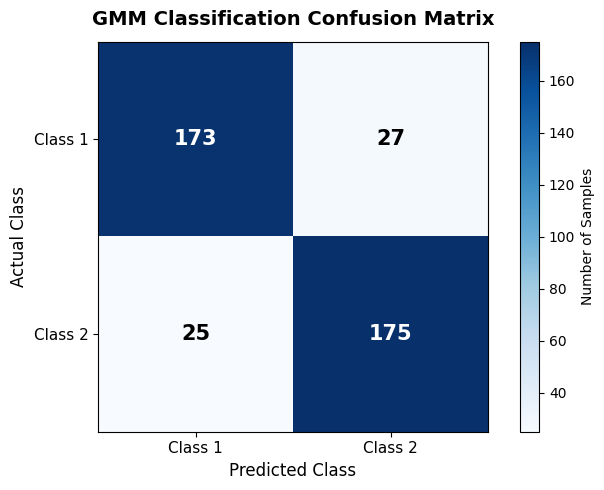

In [13]:
# Plot confusion matrix
plt.figure(figsize=(7, 5))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("GMM Classification Confusion Matrix",
          fontsize=14, fontweight="bold", pad=12)

plt.colorbar(label="Number of Samples")

# Axis labels
plt.xticks([0, 1], ["Class 1", "Class 2"], fontsize=11)
plt.yticks([0, 1], ["Class 1", "Class 2"], fontsize=11)

plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

# Display values with contrasting text colours
threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, f"{cm[i, j]}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=15,
            fontweight="bold"
        )

plt.tight_layout()
plt.show()


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# Replace these with your team's assigned digits
assigned_digits = [0, 1, 2]

np.random.seed(42)

In [15]:
# Load MNIST dataset
(X_train_all, y_train_all), (X_test_all, y_test_all) = mnist.load_data()

# Flatten each 28x28 image into 784 pixel values
X_train_all = X_train_all.reshape(-1, 784).astype("float32") / 255.0
X_test_all = X_test_all.reshape(-1, 784).astype("float32") / 255.0

# Select only the three assigned digits
train_mask = np.isin(y_train_all, assigned_digits)
test_mask = np.isin(y_test_all, assigned_digits)

X_train = X_train_all[train_mask]
y_train = y_train_all[train_mask]

X_test = X_test_all[test_mask]
y_test = y_test_all[test_mask]

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Selected digits:", assigned_digits)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 18623
Testing samples: 3147
Selected digits: [0, 1, 2]


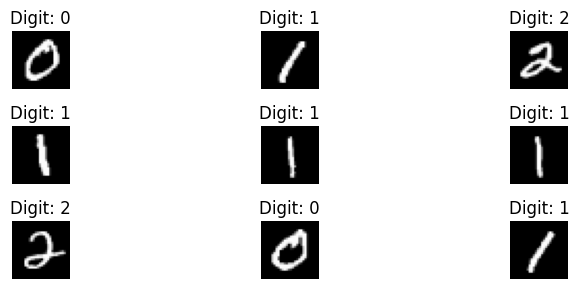

In [16]:
plt.figure(figsize=(9, 3))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title("Digit: " + str(y_train[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
pca = PCA(n_components=40, random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Original features:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])

print("Variance retained:",
      round(np.sum(pca.explained_variance_ratio_) * 100, 2), "%")

Original features: 784
Features after PCA: 40
Variance retained: 83.79 %


In [19]:
gmm_models = {}

for digit in assigned_digits:
    # Select training data for this digit
    digit_data = X_train_pca[y_train == digit]

    # Train the GMM
    gmm = GaussianMixture(
        n_components=3,
        covariance_type="full",
        random_state=42,
        n_init=2,
        reg_covar=1e-5,
        max_iter=100
    )

    gmm.fit(digit_data)
    gmm_models[digit] = gmm

    print("GMM trained for digit:", digit)

GMM trained for digit: 0
GMM trained for digit: 1
GMM trained for digit: 2


In [20]:
# Calculate log-likelihood under each digit's GMM
log_likelihoods = []

for digit in assigned_digits:
    scores = gmm_models[digit].score_samples(X_test_pca)
    log_likelihoods.append(scores)

log_likelihoods = np.array(log_likelihoods).T

# Select the digit with the highest likelihood
predicted_indices = np.argmax(log_likelihoods, axis=1)
y_pred = np.array(assigned_digits)[predicted_indices]

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=assigned_digits,
    zero_division=0
))

Test Accuracy: 99.78 %

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       980
           1       1.00      1.00      1.00      1135
           2       1.00      1.00      1.00      1032

    accuracy                           1.00      3147
   macro avg       1.00      1.00      1.00      3147
weighted avg       1.00      1.00      1.00      3147



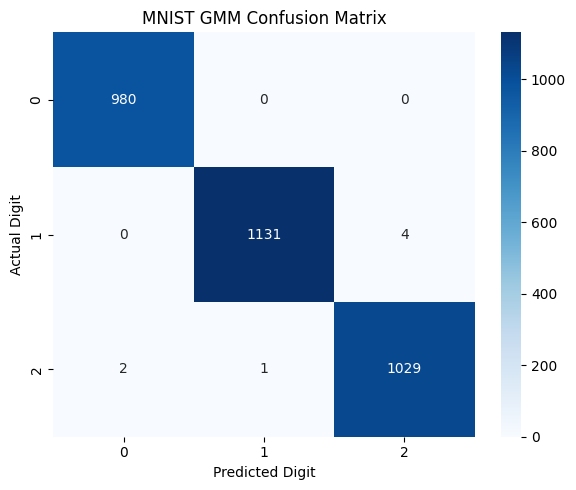

In [22]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=assigned_digits
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=assigned_digits,
    yticklabels=assigned_digits
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("MNIST GMM Confusion Matrix")
plt.tight_layout()
plt.show()

Number of misclassified images: 7


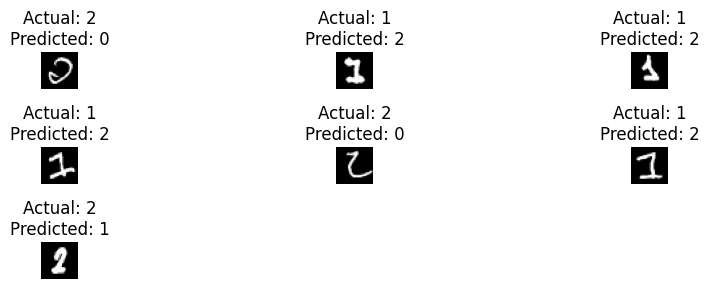

In [23]:
wrong_indices = np.where(y_test != y_pred)[0]

print("Number of misclassified images:", len(wrong_indices))

if len(wrong_indices) > 0:
    number_to_show = min(9, len(wrong_indices))

    plt.figure(figsize=(9, 3))

    for i in range(number_to_show):
        idx = wrong_indices[i]

        plt.subplot(3, 3, i + 1)
        plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
        plt.title(
            "Actual: " + str(y_test[idx]) +
            "\nPredicted: " + str(y_pred[idx])
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images.")

In [24]:
print("Per-digit accuracy:")

for digit in assigned_digits:
    mask = (y_test == digit)
    digit_accuracy = accuracy_score(y_test[mask], y_pred[mask])

    print(
        "Digit", digit, ":",
        round(digit_accuracy * 100, 2), "%"
    )

Per-digit accuracy:
Digit 0 : 100.0 %
Digit 1 : 99.65 %
Digit 2 : 99.71 %
